<a href="https://colab.research.google.com/github/Kkurzo/-labs/blob/main/%22%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9C%D0%B5%D0%BB%D1%8C%D0%BD%D0%B8%D1%87%D1%83%D0%BA_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%BE_%D0%A4%D0%86%D0%A2_4_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()

df_iris = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("Перші п'ять рядків набору Iris:")
display(df_iris.head())

print("\nРозмір набору даних:", df_iris.shape)

print("\nНазви ознак:")
print(df_iris.columns.tolist())

Перші п'ять рядків набору Iris:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Розмір набору даних: (150, 4)

Назви ознак:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

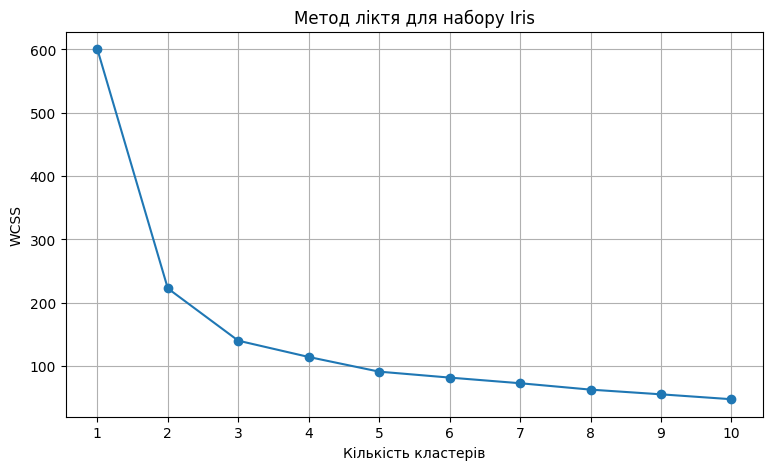

In [3]:
scaler_iris = StandardScaler()

X_iris_scaled = scaler_iris.fit_transform(df_iris)

wcss_iris = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_iris_scaled)

    wcss_iris.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss_iris,
    marker='o'
)

plt.title("Метод ліктя для набору Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

Кількість кластерів: 2, коефіцієнт силуета: 0.5818
Кількість кластерів: 3, коефіцієнт силуета: 0.4599
Кількість кластерів: 4, коефіцієнт силуета: 0.3869
Кількість кластерів: 5, коефіцієнт силуета: 0.3459
Кількість кластерів: 6, коефіцієнт силуета: 0.3171
Кількість кластерів: 7, коефіцієнт силуета: 0.3202
Кількість кластерів: 8, коефіцієнт силуета: 0.3387
Кількість кластерів: 9, коефіцієнт силуета: 0.3424
Кількість кластерів: 10, коефіцієнт силуета: 0.3518


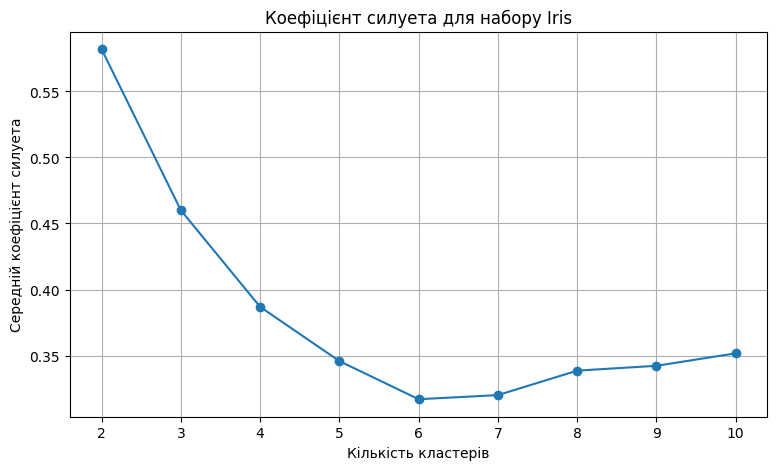

In [4]:
silhouette_scores_iris = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_iris_scaled)

    score = silhouette_score(
        X_iris_scaled,
        labels
    )

    silhouette_scores_iris.append(score)

    print(f"Кількість кластерів: {k}, "
          f"коефіцієнт силуета: {score:.4f}")

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores_iris,
    marker='o'
)

plt.title("Коефіцієнт силуета для набору Iris")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

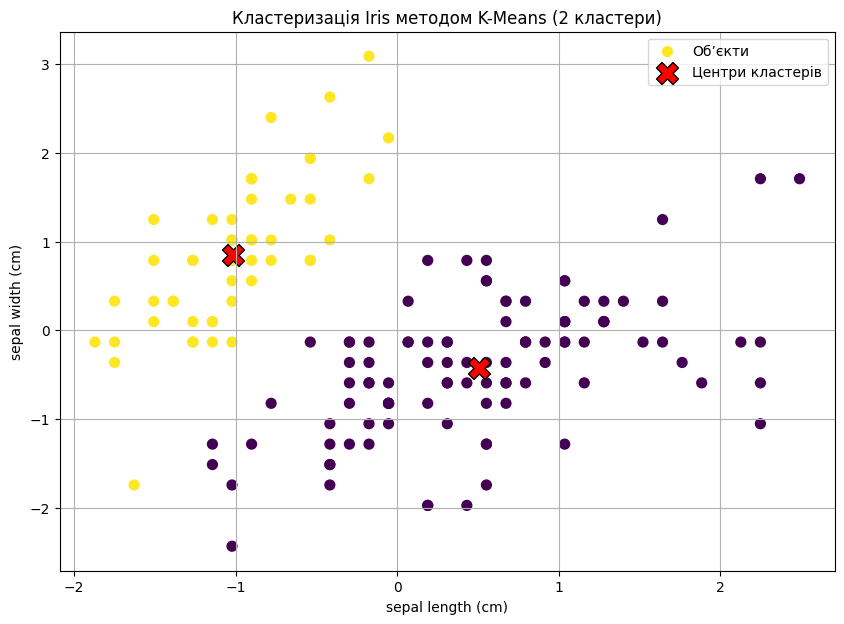

Кількість об'єктів у кожному кластері:
0    100
1     50
Name: count, dtype: int64

Координати центрів кластерів:
[[ 0.50728948 -0.42663134]
 [-1.01457897  0.85326268]]


In [5]:
kmeans_iris = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

iris_clusters = kmeans_iris.fit_predict(X_iris_scaled)

centers_iris = kmeans_iris.cluster_centers_

plt.figure(figsize=(10, 7))

plt.scatter(
    X_iris_scaled[:, 0],
    X_iris_scaled[:, 1],
    c=iris_clusters,
    cmap='viridis',
    s=50,
    label='Об’єкти'
)

plt.scatter(
    centers_iris[:, 0],
    centers_iris[:, 1],
    c='red',
    marker='X',
    s=250,
    edgecolors='black',
    label='Центри кластерів'
)

plt.title("Кластеризація Iris методом K-Means (2 кластери)")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.legend()
plt.grid(True)
plt.show()

print("Кількість об'єктів у кожному кластері:")
print(pd.Series(iris_clusters).value_counts().sort_index())

print("\nКоординати центрів кластерів:")
print(centers_iris[:, :2])

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [12]:
for column in df.columns:
    print(column)

StudentID
Age
Gender
Ethnicity
ParentalEducation
StudyTimeWeekly
Absences
Tutoring
ParentalSupport
Extracurricular
Sports
Music
Volunteering
GPA
GradeClass


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [15]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [18]:
duplicates = df.duplicated().sum()

print("Кількість дублікатів:", duplicates)

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [21]:
display(df.describe())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [22]:
X = df.drop(
    columns=['GradeClass', 'StudentID']
)

y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір тренувальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nКласи цільової змінної:")
print(y.value_counts().sort_index())

Розмір тренувальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)

Класи цільової змінної:
GradeClass
0.0     107
1.0     269
2.0     391
3.0     414
4.0    1211
Name: count, dtype: int64


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [23]:
rf = RandomForestClassifier(
    random_state=42
)

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

rf_best = rf_grid.best_estimator_

rf_cv = rf_grid.best_score_

rf_pred = rf_best.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Найкращі параметри Random Forest:")
print(rf_grid.best_params_)

print("\nСередня CV-точність:", round(rf_cv, 4))
print("Тестова Accuracy:", round(rf_accuracy, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри Random Forest:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Середня CV-точність: 0.9205
Тестова Accuracy: 0.9102


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [24]:
lr = LogisticRegression(
    max_iter=5000,
    random_state=42
)

lr_params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'saga']
}

lr_grid = GridSearchCV(
    estimator=lr,
    param_grid=lr_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train_scaled, y_train)

lr_best = lr_grid.best_estimator_

lr_cv = lr_grid.best_score_

lr_pred = lr_best.predict(X_test_scaled)

lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

print("Найкращі параметри Logistic Regression:")
print(lr_grid.best_params_)

print("\nСередня CV-точність:", round(lr_cv, 4))
print("Тестова Accuracy:", round(lr_accuracy, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Найкращі параметри Logistic Regression:
{'C': 100, 'solver': 'lbfgs'}

Середня CV-точність: 0.7977
Тестова Accuracy: 0.7912


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [25]:
svm = SVC()

svm_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    estimator=svm,
    param_grid=svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train_scaled, y_train)

svm_best = svm_grid.best_estimator_

svm_cv = svm_grid.best_score_

svm_pred = svm_best.predict(X_test_scaled)

svm_accuracy = accuracy_score(
    y_test,
    svm_pred
)

print("Найкращі параметри SVM:")
print(svm_grid.best_params_)

print("\nСередня CV-точність:", round(svm_cv, 4))
print("Тестова Accuracy:", round(svm_accuracy, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри SVM:
{'C': 100, 'gamma': 'scale', 'kernel': 'linear'}

Середня CV-точність: 0.8547
Тестова Accuracy: 0.8497


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

Порівняння моделей:


,Модель,CV Accuracy,Test Accuracy
0,Random Forest,0.920549,0.910230
2,SVM,0.854677,0.849687
1,Logistic Regression,0.797695,0.791232


<Figure size 900x500 with 0 Axes>

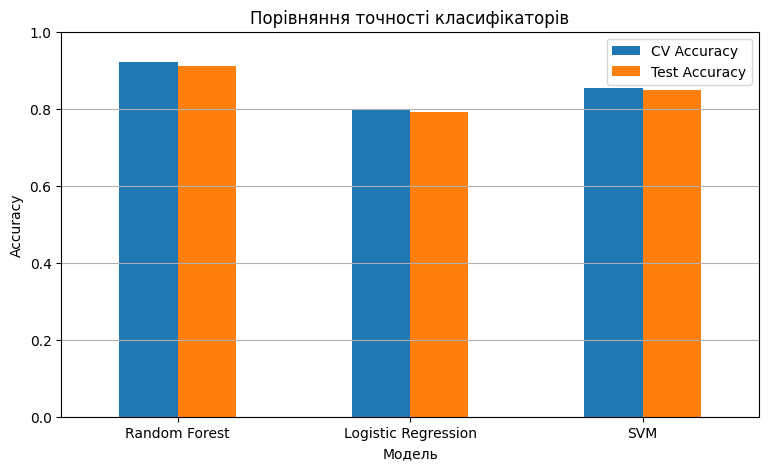

Найкраща модель за CV Accuracy: Random Forest

Звіт класифікації для найкращої моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



In [26]:
results = pd.DataFrame({
    'Модель': [
        'Random Forest',
        'Logistic Regression',
        'SVM'
    ],
    'CV Accuracy': [
        rf_cv,
        lr_cv,
        svm_cv
    ],
    'Test Accuracy': [
        rf_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

print("Порівняння моделей:")
display(results.sort_values(
    by='CV Accuracy',
    ascending=False
))

plt.figure(figsize=(9, 5))

results.plot(
    x='Модель',
    y=['CV Accuracy', 'Test Accuracy'],
    kind='bar',
    figsize=(9, 5)
)

plt.title("Порівняння точності класифікаторів")
plt.xlabel("Модель")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

best_model_name = results.loc[
    results['CV Accuracy'].idxmax(),
    'Модель'
]

print("Найкраща модель за CV Accuracy:", best_model_name)

predictions = {
    'Random Forest': rf_pred,
    'Logistic Regression': lr_pred,
    'SVM': svm_pred
}

best_predictions = predictions[best_model_name]

print("\nЗвіт класифікації для найкращої моделі:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

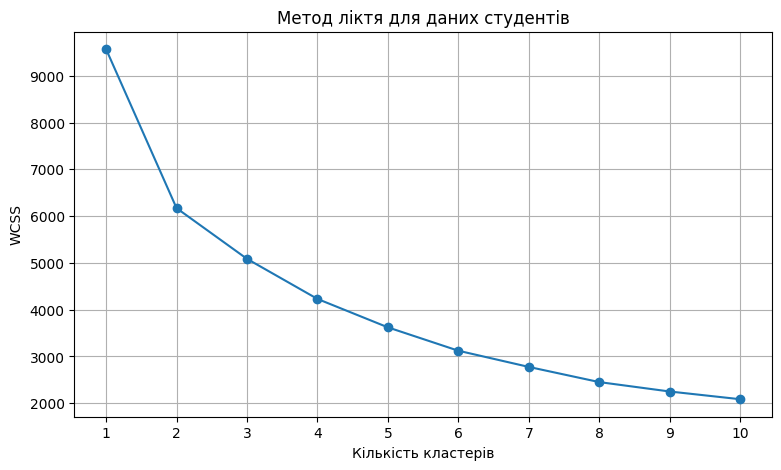

In [27]:
student_features = [
    'Age',
    'StudyTimeWeekly',
    'Absences',
    'GPA'
]

X_students = df[student_features].copy()

scaler_students = StandardScaler()

X_students_scaled = scaler_students.fit_transform(
    X_students
)

wcss_students = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_students_scaled)

    wcss_students.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, 11),
    wcss_students,
    marker='o'
)

plt.title("Метод ліктя для даних студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

Кластерів: 2, коефіцієнт силуета: 0.3080
Кластерів: 3, коефіцієнт силуета: 0.2702
Кластерів: 4, коефіцієнт силуета: 0.2580
Кластерів: 5, коефіцієнт силуета: 0.2645
Кластерів: 6, коефіцієнт силуета: 0.2689
Кластерів: 7, коефіцієнт силуета: 0.2692
Кластерів: 8, коефіцієнт силуета: 0.2712
Кластерів: 9, коефіцієнт силуета: 0.2732
Кластерів: 10, коефіцієнт силуета: 0.2725


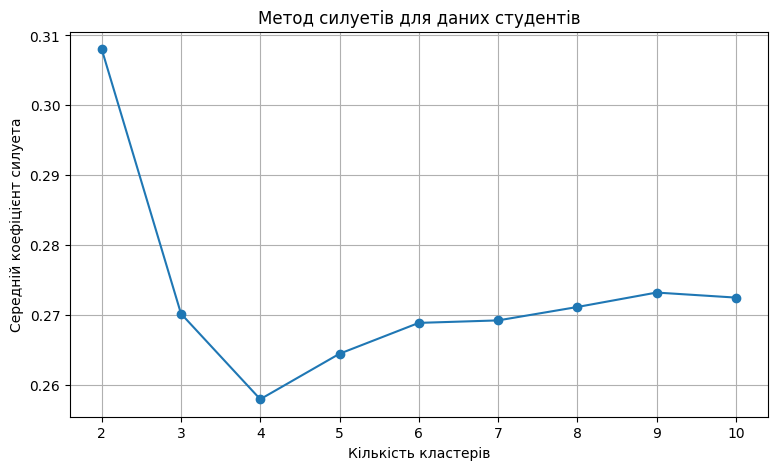

In [28]:
silhouette_scores_students = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        X_students_scaled
    )

    score = silhouette_score(
        X_students_scaled,
        labels
    )

    silhouette_scores_students.append(score)

    print(
        f"Кластерів: {k}, "
        f"коефіцієнт силуета: {score:.4f}"
    )

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores_students,
    marker='o'
)

plt.title("Метод силуетів для даних студентів")
plt.xlabel("Кількість кластерів")
plt.ylabel("Середній коефіцієнт силуета")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [29]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [30]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [31]:
X_pca = df.drop(
    columns=['StudentID', 'GradeClass']
).copy()

print("Ознаки для PCA:")
print(X_pca.columns.tolist())

print("\nРозмір даних:")
print(X_pca.shape)

print("\nТипи даних:")
print(X_pca.dtypes)

Ознаки для PCA:
['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']

Розмір даних:
(2392, 13)

Типи даних:
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
dtype: object


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [32]:
scaler_pca = StandardScaler()

X_pca_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA()

X_pca_transformed = pca.fit_transform(
    X_pca_scaled
)

explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:")

for i, variance in enumerate(explained_variance):
    print(
        f"Компонента {i}: {variance:.4f} "
        f"({variance * 100:.2f}%)"
    )

Частка поясненої дисперсії кожної компоненти:
Компонента 0: 0.1525 (15.25%)
Компонента 1: 0.0861 (8.61%)
Компонента 2: 0.0827 (8.27%)
Компонента 3: 0.0807 (8.07%)
Компонента 4: 0.0786 (7.86%)
Компонента 5: 0.0779 (7.79%)
Компонента 6: 0.0763 (7.63%)
Компонента 7: 0.0760 (7.60%)
Компонента 8: 0.0744 (7.44%)
Компонента 9: 0.0738 (7.38%)
Компонента 10: 0.0717 (7.17%)
Компонента 11: 0.0675 (6.75%)
Компонента 12: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

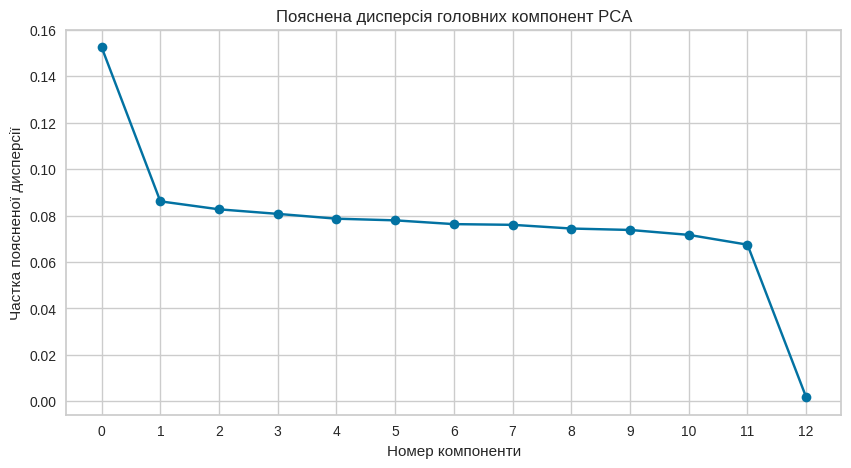

Оптимальна кількість компонент: 1


In [33]:
components = np.arange(len(explained_variance))

plt.figure(figsize=(10, 5))

plt.plot(
    components,
    explained_variance,
    marker='o'
)

plt.title("Пояснена дисперсія головних компонент PCA")
plt.xlabel("Номер компоненти")
plt.ylabel("Частка поясненої дисперсії")
plt.xticks(components)
plt.grid(True)
plt.show()

knee_pca = KneeLocator(
    components,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

optimal_components = knee_pca.knee

print("Оптимальна кількість компонент:", optimal_components)

if optimal_components is None:
    print("Автоматично визначити точку перегину не вдалося.")

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Кількість вибраних компонент: 2
Фактична кумулятивна частка дисперсії: 0.2386


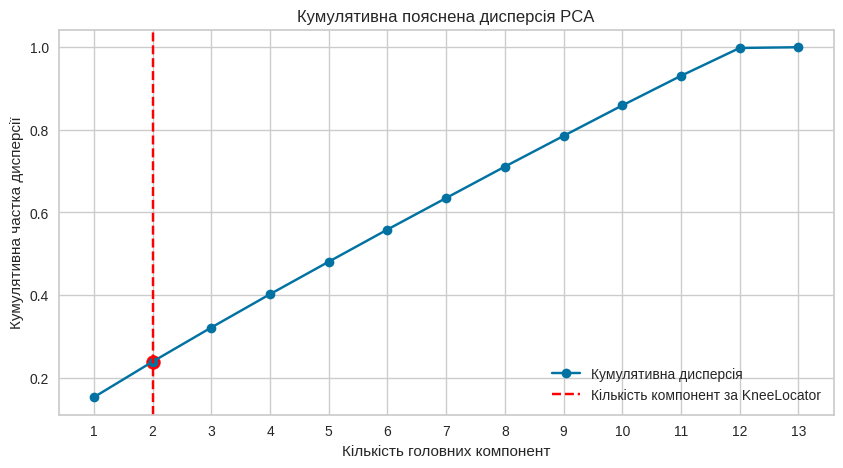


Розмір даних після PCA:
(2392, 2)


In [34]:
cumulative_variance = np.cumsum(
    explained_variance
)

component_numbers = np.arange(
    1,
    len(cumulative_variance) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    component_numbers,
    cumulative_variance,
    marker='o',
    label='Кумулятивна дисперсія'
)

if optimal_components is not None:
    plt.axvline(
        x=optimal_components + 1,
        color='red',
        linestyle='--',
        label='Кількість компонент за KneeLocator'
    )

    selected_variance = cumulative_variance[
        optimal_components
    ]

    plt.scatter(
        optimal_components + 1,
        selected_variance,
        color='red',
        s=100
    )

    print(
        "Кількість вибраних компонент:",
        optimal_components + 1
    )

    print(
        "Фактична кумулятивна частка дисперсії:",
        round(selected_variance, 4)
    )

plt.title("Кумулятивна пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна частка дисперсії")
plt.xticks(component_numbers)
plt.grid(True)
plt.legend()
plt.show()

if optimal_components is not None:
    n_components = optimal_components + 1
else:

    n_components = np.argmax(
        cumulative_variance >= 0.90
    ) + 1

pca_final = PCA(
    n_components=n_components
)

X_pca_final = pca_final.fit_transform(
    X_pca_scaled
)

print("\nРозмір даних після PCA:")
print(X_pca_final.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [35]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

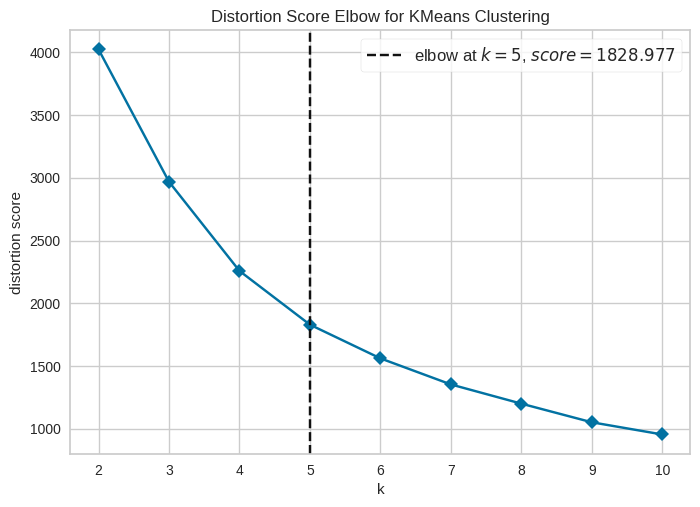

Оптимальна кількість кластерів за методом ліктя: 5


In [36]:
model = KMeans(
    random_state=42,
    n_init=10
)

visualizer = KElbowVisualizer(
    model,
    k=(2, 11),
    metric='distortion',
    timings=False
)

visualizer.fit(X_pca_final)

visualizer.show()

print(
    "Оптимальна кількість кластерів за методом ліктя:",
    visualizer.elbow_value_
)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.